# Lesson 10 - CWRU Bearing Fault Frequency Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.io import loadmat
from scipy.stats import kurtosis

In [2]:
# Define the data path
cwd = Path.cwd()

if (cwd / "data").exists():
    project_root = cwd
elif (cwd.parent / "data").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Could not find project data folder")

data_dir = (project_root / "data" / "cwru" / "raw")

print(data_dir)
list(data_dir.iterdir())

c:\Users\User\Documents\Projects\predictive-maintenance-system\data\cwru\raw


[WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/109.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/122.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/135.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/97.mat')]

In [3]:
# File Loader
def load_cwru_file(file_path, channel="DE_time"):
    data = loadmat(file_path)

    keys = [
        key
        for key in data.keys()
        if not key.startswith("__")
    ]

    signal_key = next(
        key
        for key in keys
        if channel in key
    )

    rpm_key = next(
        (
            key
            for key in keys
            if "RPM" in key
        ),
        None
    )

    signal = data[signal_key].squeeze()

    rpm = None
    if rpm_key is not None:
        rpm = float(
            np.asarray(
                data[rpm_key]
            ).squeeze()
        )

    return signal, rpm

In [4]:
# Load all four conditions
files = {
    "Normal": "97.mat",
    "Inner race": "109.mat",
    "Ball": "122.mat",
    "Outer race": "135.mat"
}

signals = {}
rpms = {}

for condition, filename in files.items():
    signal, rpm = load_cwru_file(data_dir / filename)
    signals[condition] = signal
    rpms[condition] = rpm

rpms

{'Normal': 1796.0, 'Inner race': 1796.0, 'Ball': 1796.0, 'Outer race': 1796.0}

### CWRU Mulitpliers

Drive end bearing: 6205-2RS JEM SKF, deep groove ball bearing
- BPFI: Ball Pass Frequency Inner race
- BPFO: Ball Pass Frequency Outer race
- FTF: Fundamental Train Frequency (Cage Train)
- Rolling Element

In [5]:
# Add CWRU multipliers
CWRU_MULTIPLIERS = {
    "bpfi": 5.4152,
    "bpfo": 3.5848,
    "ftf": 0.39828,
    "rolling_element": 4.7135
}

In [6]:
# Function for calculating bearing frequencies
def calculate_bearing_frequencies(rpm):
    shaft_frequency = rpm / 60

    return {
        "shaft": shaft_frequency,
        "bpfi": CWRU_MULTIPLIERS["bpfi"] * shaft_frequency,
        "bpfo": CWRU_MULTIPLIERS["bpfo"] * shaft_frequency,
        "ftf": CWRU_MULTIPLIERS["ftf"] * shaft_frequency,
        "rolling_element": CWRU_MULTIPLIERS["rolling_element"] * shaft_frequency
    }

In [13]:
# Calculate using rpm from data
frequency_rows = []

for condition, rpm in rpms.items():
    fault_frequencies = calculate_bearing_frequencies(rpm)
    fault_frequencies["condition"] = condition
    fault_frequencies["rpm"] = rpm

    frequency_rows.append(fault_frequencies)

In [16]:
# Create DataFrame
bearing_frequency_df = pd.DataFrame(frequency_rows)

bearing_frequency_df

,shaft,bpfi,bpfo,ftf,rolling_element,condition,rpm
0,29.933333,162.094987,107.305013,11.921848,141.090767,Normal,1796.0
1,29.933333,162.094987,107.305013,11.921848,141.090767,Inner race,1796.0
2,29.933333,162.094987,107.305013,11.921848,141.090767,Ball,1796.0
3,29.933333,162.094987,107.305013,11.921848,141.090767,Outer race,1796.0


In [17]:
# Inspect recording lengths
sampling_rate = 48000

for condition, signal in signals.items():
    duration = len(signal) / sampling_rate

    print(
        f"{condition:12}"
        f"samples = {len(signal):8d} "
        f"duration = {duration:.2f} s "
        f"RPM = {rpms[condition]}"
    )

Normal      samples =   243938 duration = 5.08 s RPM = 1796.0
Inner race  samples =   243938 duration = 5.08 s RPM = 1796.0
Ball        samples =   244739 duration = 5.10 s RPM = 1796.0
Outer race  samples =   243538 duration = 5.07 s RPM = 1796.0


In [ ]:
# Use 2 second vibration segment for a better frequency resolution
analysis_duration = 2.0
analysis_samples = int(sampling_rate * analysis_duration)

In [19]:
# Create analysis window
analysis_windows = {}

for condition, signal in signals.items():
    analysis_windows[condition] = signal[:analysis_samples]

In [20]:
# Convert time-domain to frequency-domain using FFT
def calculate_fft(signal, sampling_rate):
    N = len(signal)
    centered_signal = (signal - np.mean(signal))

    # Use Hann window
    window = np.hanning(N)
    windowed_signal = (centered_signal * window)
    coherent_gain = np.mean(window)

    fft_values = np.fft.rfft(windowed_signal)
    frequencies = np.fft.rfftfreq(N, d=1 / sampling_rate)
    amplitudes = (2 / (N * coherent_gain)) * np.abs(fft_values)

    amplitudes[0] /= 2
    if N % 2 == 0:
        amplitudes[-1] /= 2

    return frequencies, amplitudes

In [ ]:
# Start with Outer-race fault
condition = "Outer race"
signal = analysis_windows[condition]
rpm = rpms[condition]
fault_freqs = calculate_bearing_frequencies(rpm)
frequencies, amplitudes = calculate_fft(signal, sampling_rate)

In [22]:
# Expected outer race frequency
expected_bpfo = fault_frequencies["bpfo"]
print("Expected BPFO:", expected_bpfo, "Hz")

Expected BPFO: 107.30501333333333 Hz


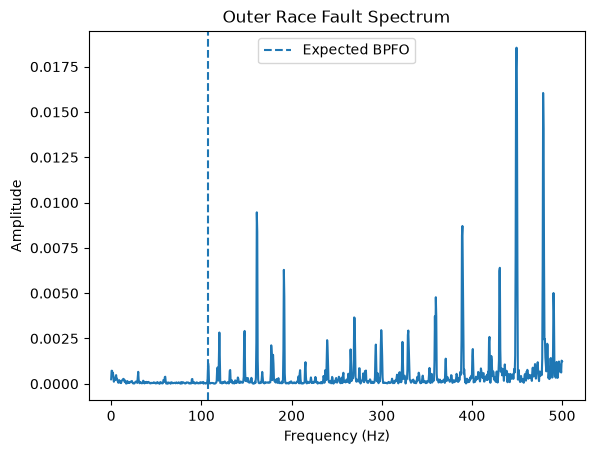

In [25]:
# Plot graph
mask = frequencies <= 500

plt.plot(frequencies[mask], amplitudes[mask])

# Add a vertical line at the x axis (expected frequency)
plt.axvline(expected_bpfo, linestyle="--", label="Expected BPFO")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Outer Race Fault Spectrum")
plt.legend()
plt.show()

In [26]:
# Search near the theoretical frequency
def find_peak_near(frequencies, amplitudes, target_frequency, search_width=5):
    # Find frequencies within target_frequency +- search_width
    mask = (
        frequencies >= target_frequency - search_width
    ) & (
        frequencies <= target_frequency + search_width
    )

    local_frequency = frequencies[mask]
    local_amplitude = amplitudes[mask]
    local_peak_index = np.argmax(local_amplitude)

    return local_frequency[local_peak_index], local_amplitude[local_peak_index]

In [28]:
# Find the peak frequency and amplitude
peak_frequency, peak_amplitude = find_peak_near(frequencies, amplitudes, expected_bpfo)

print("Expected BPFO:", expected_bpfo)
print("Strongest nearby peak:", peak_frequency)
print("Nearby Amplitude:", peak_amplitude)

Expected BPFO: 107.30501333333333
Strongest nearby peak: 107.5
Nearby Amplitude: 0.0011331250718848072


In [31]:
# Compare error
frequency_error = peak_frequency - expected_bpfo
percentage_error = abs(frequency_error) / expected_bpfo * 100

print(f"Frequency difference: {frequency_error:.2f} Hz")
print(f"Relative difference: {percentage_error:.2f}%")

Frequency difference: 0.19 Hz
Relative difference: 0.18%


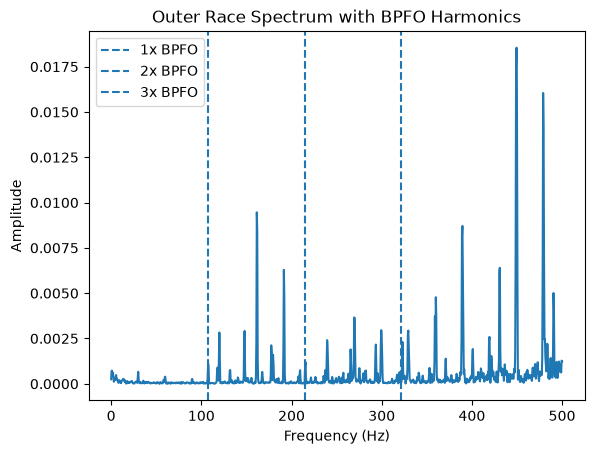

In [33]:
# Look for harmonics (1X, 2X, 3X)
mask = frequencies <= 500

plt.plot(frequencies[mask], amplitudes[mask])

# Add a vertical line at the x axis (expected frequency)
for harmonic in range(1, 4):
    harmonic_frequency = harmonic * expected_bpfo
    plt.axvline(harmonic_frequency, linestyle="--", label=f"{harmonic}x BPFO")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Outer Race Spectrum with BPFO Harmonics")
plt.legend()
plt.show()


## Mechanical Interpretation

In the raw acceleration FFT, no dominant component was observed directly at the theoretical BPFO. This shows that the direct FFT spectrum is not enough to identify the fault. Therefore, envelope analysis is required to obtain more information.

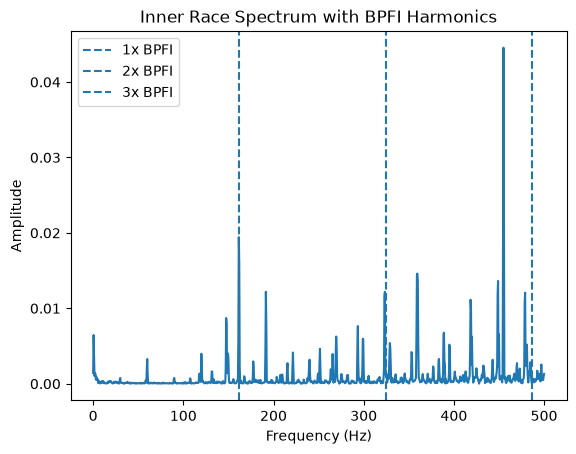

In [35]:
# For inner race
condition = "Inner race"
signal = analysis_windows[condition]
rpm = rpms[condition]
fault_freqs = calculate_bearing_frequencies(rpm)
frequencies, amplitudes = calculate_fft(signal, sampling_rate)

expected_frequency = fault_freqs["bpfi"]

# Plot graph
mask = frequencies <= 500

plt.plot(frequencies[mask], amplitudes[mask])

# Add a vertical line at the x axis (expected frequency)
for harmonic in range(1, 4):
    harmonic_frequency = harmonic * expected_frequency
    plt.axvline(harmonic_frequency, linestyle="--", label=f"{harmonic}x BPFI")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Inner Race Spectrum with BPFI Harmonics")
plt.legend()
plt.show()

## Mechanical Interpretation

In the raw acceleration FFT, there is a peak noticed at the 1x BPFI (approx. 161 Hz) and one more around the 2x BPFI (approx. 323 Hz) area. However, the peak is still small compared to the high peak near approx. 450 Hz. Moreover, there are some peaks in the sidebands as well (approx. 161 + 30 = 191 Hz). Envelope analysis is still required to obtain more information. Not only so, this graph needs to be compared with the normal condition to analyze whether the peaks are caused by the fault itself or not.

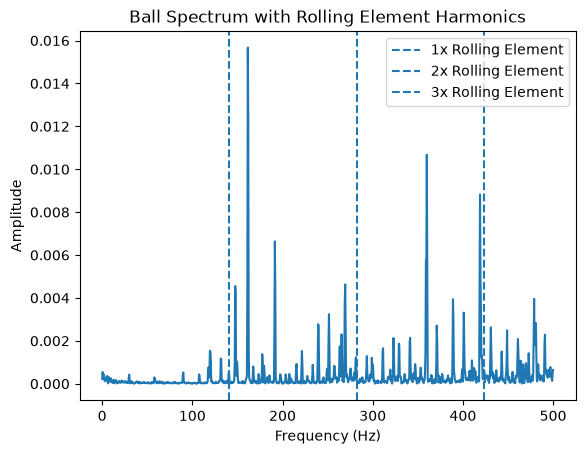

In [ ]:
# For ball
condition = "Ball"
signal = analysis_windows[condition]
rpm = rpms[condition]
fault_freqs = calculate_bearing_frequencies(rpm)
frequencies, amplitudes = calculate_fft(signal, sampling_rate)

expected_frequency = fault_freqs["rolling_element"]

# Plot graph
mask = frequencies <= 500

plt.plot(frequencies[mask], amplitudes[mask])

# Add a vertical line at the x axis (expected frequency)
for harmonic in range(1, 4):
    harmonic_frequency = harmonic * expected_frequency
    plt.axvline(harmonic_frequency, linestyle="--", label=f"{harmonic}x Rolling Element")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Ball Spectrum with Rolling Element Harmonics")
plt.legend()
plt.show()

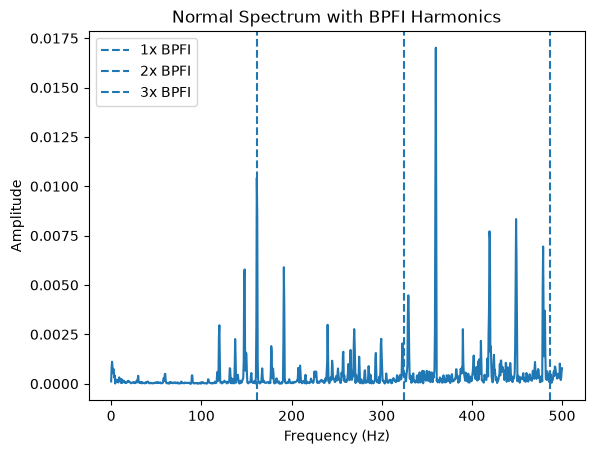

In [41]:
# Use normal as baseline comparison
condition = "Normal"
signal = analysis_windows[condition]
rpm = rpms[condition]
fault_freqs = calculate_bearing_frequencies(rpm)
frequencies, amplitudes = calculate_fft(signal, sampling_rate)

expected_frequency = fault_freqs["bpfi"]

# Plot graph
mask = frequencies <= 500

plt.plot(frequencies[mask], amplitudes[mask])

# Add a vertical line at the x axis (expected frequency)
for harmonic in range(1, 4):
    harmonic_frequency = harmonic * expected_frequency
    plt.axvline(harmonic_frequency, linestyle="--", label=f"{harmonic}x BPFI")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Normal Spectrum with BPFI Harmonics")
plt.legend()
plt.show()

## Mechanical Interpretation

In this graph, the previous 1x BPFI peak (approx. 161 Hz) was also observed in the normal condition with a smaller amplitude. Therefore, it can't be proven whether this frequency indicates bearing damage or if it is just normal machine noise, since the healthy condition also has the vibration. Therefore, this shows that direct raw FFT alone is not enough to identify the fault, and envelope analysis is required.

In [42]:
# Show comparison
expected_fault = {
    "Inner race": "bpfi",
    "Ball": "rolling_element",
    "Outer race": "bpfo"
}

In [43]:
# Compare them
comparison_rows = []

for condition, fault_name in expected_fault.items():
    signal = analysis_windows[condition]
    rpm = rpms[condition]
    fault_freqs = calculate_bearing_frequencies(rpm)

    expected_frequency = fault_freqs[fault_name]
    frequencies, amplitudes = calculate_fft(signal, sampling_rate)
    peak_frequency, peak_amplitude = find_peak_near(frequencies, amplitudes, expected_frequency)

    comparison_rows.append({
        "condition": condition,
        "rpm": rpm,
        "expected_type": fault_name,
        "expected_frequency": expected_frequency,
        "nearby_peak_frequency": peak_frequency,
        "frequency_difference": peak_frequency - expected_frequency,
        "peak_amplitude": peak_amplitude
    })

In [44]:
# Create DataFrame
fault_frequency_comparison = pd.DataFrame(comparison_rows)

fault_frequency_comparison

,condition,rpm,expected_type,expected_frequency,nearby_peak_frequency,frequency_difference,peak_amplitude
0,Inner race,1796.0,bpfi,162.094987,161.5,-0.594987,0.019435
1,Ball,1796.0,rolling_element,141.090767,140.5,-0.590767,0.000556
2,Outer race,1796.0,bpfo,107.305013,107.5,0.194987,0.001133
